In [2]:
# laden der Packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sn

from scipy.stats import norm
from scipy.stats import binom
from scipy.stats import hypergeom
from scipy.stats import t
from scipy.stats import chi2

In [2]:
import warnings
warnings.filterwarnings("ignore")

# Stetige Verteilungen


### Ziele der Übung

- Zufallsvariablen und dessen Erwartungswerte
- Verteilungen pdf und cdf
- Stetige Verteilungen: Normalverteilung, t-Verteilung $\chi^2$ Verteilung

**Hilfestellung:**
- Informationen zur Normalverteilung in Python: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html
- Informationen zur t Verteilung in Python: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html
- Informationen zur $\chi^2$ Verteilung in Python: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html?highlight=chi2

## Aufgabe 1: Normalverteilung

Visualisiere in Python die pdf einer Normalverteilung mit 

- $\mu = \{3, 4, 5, 10\}$ und $\sigma = 0.5$
- $\mu = 5$ und $\sigma = \{0.1, 0.3, 0.5, 1\}$

was fällt dir auf?

**Lösung**

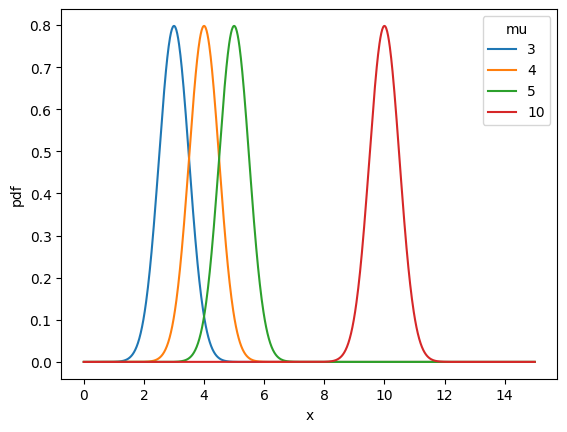

In [3]:
mu = [3, 4, 5, 10]
sigma = 0.5
x = np.linspace(0, 15, 1000)

df = pd.DataFrame()
for i in range(len(mu)):
    data = {'x':x, 'pdf': norm.pdf(x, mu[i], sigma), 'mu': str(mu[i])} 
    df1 = pd.DataFrame(data)
    df = pd.concat([df, df1], axis = 0)

sn.lineplot(data = df, x = 'x', y = 'pdf', hue  = 'mu')
plt.show;

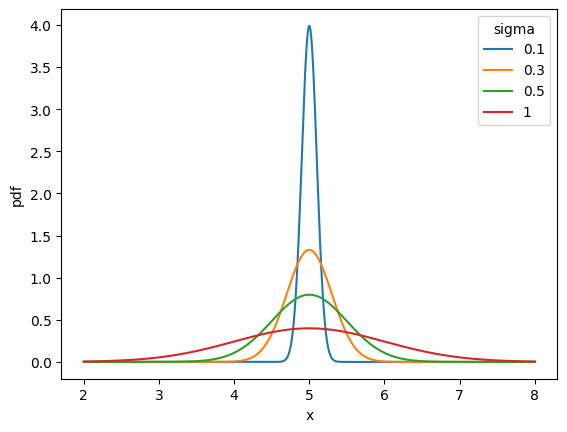

In [4]:
mu = 5
sigma = [0.1, 0.3, 0.5, 1]
x = np.linspace(2, 8, 1000)

df = pd.DataFrame()
for i in range(len(sigma)):
    data = {'x':x, 'pdf': norm.pdf(x, mu, sigma[i]), 'sigma': str(sigma[i])} 
    df1 = pd.DataFrame(data)
    df = pd.concat([df, df1], axis = 0)

sn.lineplot(data = df, x = 'x', y = 'pdf', hue  = 'sigma')
plt.show;

## Aufgabe 2: Normalverteilung

In einem Werk für Kosmetika und Seife wird Gesichtswasser maschinell in Flaschen abgefüllt. Der alte Werkmeister weiß, dass die von der Maschine abgefüllten Mengen einen Erwartungswert von 145 ccm und eine Standardabweichung von 2 ccm aufweisen und
normalverteilt sind. 

a) Visualisiere pdf und cdf. 

b) Wie groß ist die Wahrscheinlichkeit, dass eine zufällig gewählte Flasche weniger als 145 ccm besitzt?

c) Wie groß ist die Wahrscheinlichkeit, dass eine zufällig gewählte Flasche mehr als 155 ccm besitzt?

d) Wie groß ist die Wahrscheinlichkeit, dass eine zufällig gewählte Flasche zwischen 150 ccm und 155 ccm besitzt?

e) Welches Maximalvolumen wird von 90% der Flaschen unterschritten?

f) Welches Minimalvolumen wird von 90% der Flaschen überschritten?

**Lösung**

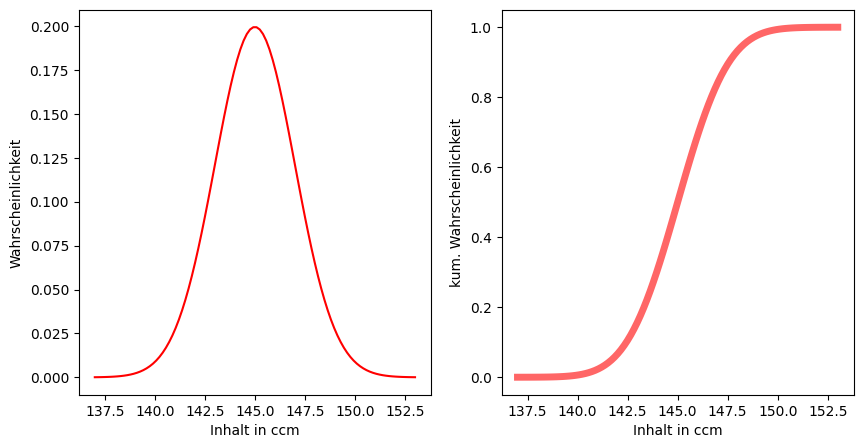

In [3]:
mu = 145
sigma = 2

x = np.linspace(mu-4*sigma, mu+4*sigma, 100)
fig, ax = plt.subplots(1, 2, figsize=(10, 5)) 

ax[0].plot(x, norm.pdf(x, loc = mu, scale = sigma), 'r')
ax[0].set_xlabel('Inhalt in ccm')
ax[0].set_ylabel('Wahrscheinlichkeit')
#plt.grid()

ax[1].plot(x, norm.cdf(x, loc = mu, scale = sigma), 'r-', lw=5, alpha=0.6, label='norm cdf')
ax[1].set_xlabel('Inhalt in ccm')
ax[1].set_ylabel('kum. Wahrscheinlichkeit');
#plt.grid()

b) Wie groß ist die Wahrscheinlichkeit, dass eine zufällig gewählte Flasche weniger als 145 ccm besitzt?

$P(X \leq 145) = 50\%$

In [4]:
## in python 

res = round(norm.cdf(145, loc = mu, scale = sigma) * 100, 2)

print('Die Wahrscheinlichkeit beträgt {}%.' .format(res))

Die Wahrscheinlichkeit beträgt 50.0%.


c) Wie groß ist die Wahrscheinlichkeit, dass eine zufällig gewählte Flasche mehr als 155 ccm besitzt?

$P(X \geq 155) = 1 -  P(X \leq 155) $

In [7]:
## in python 

res = round( (1 - norm.cdf(155, loc = mu, scale = sigma)) * 100,4)

print('Die Wahrscheinlichkeit beträgt {:.4f}%.' .format(res))

Die Wahrscheinlichkeit beträgt 0.0000%.


d) Wie groß ist die Wahrscheinlichkeit, dass eine zufällig gewählte Flasche zwischen 150 ccm und 155 ccm besitzt?

$P(150 \leq X \leq 155) = P(X \leq 155)  -  P(X \leq 150)$

In [8]:
## in python 

res = round(( norm.cdf(155, loc = mu, scale = sigma) - norm.cdf(150, loc = mu, scale = sigma) ) * 100, 2)

print('Die Wahrscheinlichkeit beträgt {}%.' .format(res))

Die Wahrscheinlichkeit beträgt 0.62%.


e) Welches Maximalvolumen wird von 90% der Flaschen unterschritten?

--> Bestimme q90

$P(X \leq x) = 0{,}90$

In [9]:
## in python 

res = round(norm.ppf(0.9, loc = mu, scale = sigma), 2)

print('90% unterschreiten das Volumen von {} ccm.' .format(res))

90% unterschreiten das Volumen von 147.56 ccm.


f) Welches Minimalvolumen wird von 90% der Flaschen überschritten?

--> Bestimme q10

$P(X \leq x) = 0{,}10$

In [10]:
## in python 

res = round(norm.ppf(0.1, loc = mu, scale = sigma), 2)

print('90% unterschreiten das Volumen von {} ccm.' .format(res))

90% unterschreiten das Volumen von 142.44 ccm.


## Aufgabe 3: Student $t$-Verteilung


Visualisiere pdf und cdf einer Student $t$-Verteilung mit Freiheitsgraden $\nu \in  [1, 3, 5, 10, 20, 30, 50, 100]$

Berechne jeweils Erwartungswert, Standardabweichung, Schiefe und Kurtosis. Was fällt auf, wenn du es mit einer Standardnormalverteilung vergleichst? 

**Lösung**

In [11]:
nu = [1, 3, 5, 10, 20, 30, 50, 100]
x = np.linspace(- 6 , 6, 1000)
df = pd.DataFrame()

for i in range(len(nu)):
    data = {'x':x, 'pdf': t.pdf(x, nu[i]), 'Freiheitsgrade': str(nu[i])} 
    df1 = pd.DataFrame(data)
    df = pd.concat([df, df1], axis = 0)  
    
# include standard normal     
data = {'x': x, 'pdf': norm.pdf(x), 'Freiheitsgrade': 'Std-Normal'}   
df1 = pd.DataFrame(data)
df = pd.concat([df, df1], axis = 0)

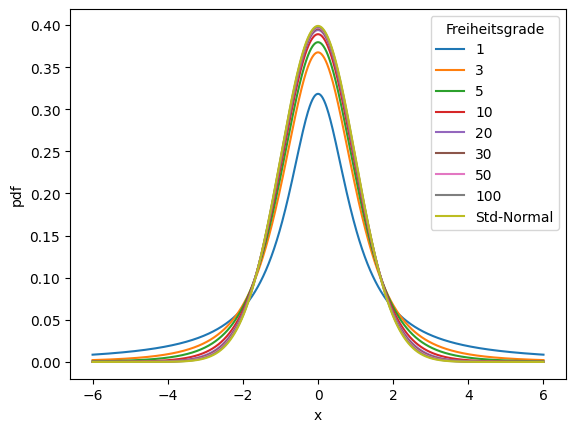

In [12]:
# for lineplot I need a new Index
df['Index'] = range(len(df))
df = df.set_index('Index')
sn.lineplot(data = df, x = 'x', y = 'pdf', hue  = 'Freiheitsgrade')
plt.show;

#plt.savefig('Std_tVerteilung.png', dpi = 300)

Je größer die Freiheitsgrade, desto mehr ähnelt die $t$-Verteilung einer Standardormalverteilung. Man sieht dies im Scatterplot und auch bei den Momenten.

Berechne jeweils Erwartungswert, Standardabweichung, Schiefe und Kurtosis. Was fällt auf, wenn du es mit einer Standardnormalverteilung vergleichst?

In [13]:
nu = [1, 3, 5, 10, 20, 30, 50, 100]
moments = pd.DataFrame()

for i in range(len(nu)):
    mean, var, skew, kurt = t.stats(nu[i], moments='mvsk')
    dataMoments = pd.DataFrame(data = [{'mean':mean, 'var': var, 'skew': skew, 'kurt': kurt, 'Freiheitsgrade': str(nu[i])} ])
    moments = pd.concat([moments, dataMoments], axis = 0)
    
moments

,mean,var,skew,kurt,Freiheitsgrade
0,inf,NaN,NaN,NaN,1
0,0.0,3.000000,NaN,inf,3
0,0.0,1.666667,0.0,6.000000,5
0,0.0,1.250000,0.0,1.000000,10
0,0.0,1.111111,0.0,0.375000,20
0,0.0,1.071429,0.0,0.230769,30
0,0.0,1.041667,0.0,0.130435,50
0,0.0,1.020408,0.0,0.062500,100


## Aufgabe 3: $\chi^2$-Verteilung


Visualisiere pdf und cdf einer $\chi^2$-Verteilung mit Freiheitsgraden $\nu \in  [2, 3, 5, 10, 20, 30]$ auf dem Intevall $0 \leq x \leq 50$. 

Berechne jeweils Erwartungswert, Standardabweichung, Schiefe und Kurtosis. Was fällt auf, wenn du es mit einer Normalverteilung vergleichst? 

**Lösung**

In [14]:
## a) 
nu = [2, 3, 5, 10, 20, 30]
x = np.linspace(0, 50, 10000)
df = pd.DataFrame()

for i in range(len(nu)):
    data = {'x':x, 'pdf': chi2.pdf(x, nu[i]), 'Freiheitsgrade': str(nu[i])} 
    df1 = pd.DataFrame(data)
    df = pd.concat([df, df1], axis = 0)

<function matplotlib.pyplot.show(close=None, block=None)>

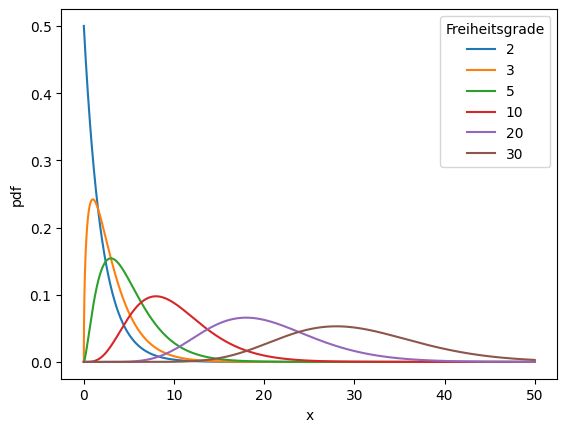

In [15]:
# for lineplot I need a new Index
df['Index'] = range(len(df))
df = df.set_index('Index')
sn.lineplot(data = df, x = 'x', y = 'pdf', hue  = 'Freiheitsgrade')
plt.show

In [16]:
nu = [2, 3, 5, 10, 20, 30]
moments = pd.DataFrame()

for i in range(len(nu)):
    mean, var, skew, kurt = chi2.stats(nu[i], moments='mvsk')
    dataMoments = pd.DataFrame(data = [{'mean':mean, 'var': var, 'skew': skew, 'kurt': kurt, 'Freiheitsgrade': str(nu[i])} ])
    moments = pd.concat([moments, dataMoments], axis = 0)
    
moments

,mean,var,skew,kurt,Freiheitsgrade
0,2.0,4.0,2.000000,6.0,2
0,3.0,6.0,1.632993,4.0,3
0,5.0,10.0,1.264911,2.4,5
0,10.0,20.0,0.894427,1.2,10
0,20.0,40.0,0.632456,0.6,20
0,30.0,60.0,0.516398,0.4,30


## Aufgabe 5: Zentraler Grenzwertsatz

Schreibe dir in Python ein kleines Programm und generiere dir 10.000 mal jeweils 1000 Realisierungen einer $\chi^2$-verteilte Zufallsvariablen mit Parameter $k = 3$. Bestimme in jeder Schleife den Mittelwert und speichere ihn in einem Vektor. Am Ende hast du einen
Vektor mit 10.000 Mittelwerten. Schau dir dessen Dichtefunktion an. Was fällt dir auf?

C:\Users\plka\Anaconda3\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\plka\Anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<AxesSubplot: ylabel='Count'>

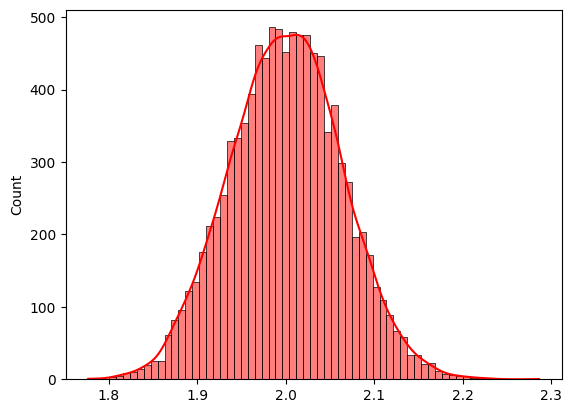

In [6]:
df = 2
n = 10000
mm_vec = []

for i in range(n):
  r = chi2.rvs(df, size = 1000) # generate random numbers
  mm = r.mean() # determine mean of the random numbers
  mm_vec = mm_vec + [mm] ## inserting the element in the array

## Plotting:
sn.histplot(mm_vec, color = "red", kde = True)

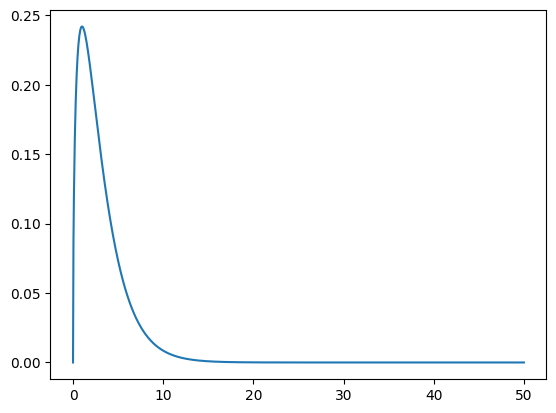

In [3]:
df = 3
x = np.linspace(0,50,1000)
pdf = chi2.pdf(x, df)
plt.plot(x, pdf)